In [50]:
import os
os.environ.pop("PYTHONPATH", None)

import sys
sys.path = [p for p in sys.path if "/opt/software-current/" not in p]

import regex
print("regex:", regex.__file__)

regex: /mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/regex/__init__.py


In [51]:
import pandas as pd
import numpy as np

df = pd.read_parquet("../../data/unsplash/clip_train.parquet")
collections_df = pd.read_csv("../../data/unsplash/collections.tsv000", sep="\t")
collections_df["collection_id"] = collections_df["collection_id"].astype(str)

df["image_path"] = [f"../../data/unsplash/{i}" for i in df["image_path"]]

In [52]:
HELDOUT_TEST = True

inject_df = pd.read_csv("../../data/small/metadata.csv")
inj = inject_df.iloc[:10].reset_index(drop=True)

new_rows = pd.DataFrame({
    "photo_id": [f"laptop_twee_{i}" for i in range(len(inj))],
    "image_path": [f"../../data/small/{p}" for p in inj["image_path"]],
    "caption": inj["caption"].astype(str),
})
df = pd.concat([df, new_rows], ignore_index=True)

all_ids = new_rows["photo_id"].tolist()
inboard_ids = all_ids[:5] if HELDOUT_TEST else all_ids
heldout_ids = all_ids[5:] if HELDOUT_TEST else []

collections_df = pd.concat([collections_df, pd.DataFrame({
    "photo_id": inboard_ids,
    "collection_id": "laptop_twee",
    "collection_title": "laptop twee",
})], ignore_index=True)

print(len(df), "photos |", len(inboard_ids), "in board |", len(heldout_ids), "held out")

25007 photos | 5 in board | 5 held out


In [53]:
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoProcessor
from sentence_transformers import SentenceTransformer
from PIL import Image

MODEL_NAME = "google/siglip2-base-patch16-224"
device = "cuda" if torch.cuda.is_available() else "cpu"

embed_model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
embed_processor = AutoProcessor.from_pretrained(MODEL_NAME)
st = SentenceTransformer("all-MiniLM-L6-v2", device=device)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 17538.70it/s]


In [54]:
def embed_images_batch(image_paths, batch_size=1024):
    embeddings = []
    for start in range(0, len(image_paths), batch_size):
        images = []
        for path in image_paths[start:start + batch_size]:
            with Image.open(path) as img:
                images.append(img.convert("RGB"))
        inputs = embed_processor(images=images, return_tensors="pt").to(device)
        with torch.inference_mode():
            out = embed_model.get_image_features(**inputs)
        out = getattr(out, "pooler_output", out)
        embeddings.append(F.normalize(out.float(), dim=-1))
    return torch.cat(embeddings)


def embed_text_batch(texts, batch_size=1024):  # SigLIP text -> matches images
    embeddings = []
    for start in range(0, len(texts), batch_size):
        inputs = embed_processor(text=texts[start:start + batch_size], padding="max_length",
                                 max_length=64, truncation=True, return_tensors="pt").to(device)
        with torch.inference_mode():
            out = embed_model.get_text_features(**inputs)
        out = getattr(out, "pooler_output", out)
        embeddings.append(F.normalize(out.float(), dim=-1))
    return torch.cat(embeddings)


def embed_text_batch_st(texts, batch_size=1024):  # sentence-transformer -> matches text
    return st.encode(texts, batch_size=batch_size, convert_to_tensor=True,
                     normalize_embeddings=True, show_progress_bar=True).float()

In [55]:
X = embed_images_batch(df["image_path"].tolist())
print(X.shape)

torch.Size([25007, 768])


In [56]:
photo_to_idx = {p: i for i, p in enumerate(df["photo_id"])}
unique_collections = (collections_df[["collection_id", "collection_title"]]
                      .drop_duplicates("collection_id").reset_index(drop=True))
collection_to_idx = {c: i for i, c in enumerate(unique_collections["collection_id"])}

titles = unique_collections["collection_title"].fillna("").astype(str).str.lower().tolist()
B = embed_text_batch_st(titles)

pc = collections_df[collections_df["photo_id"].isin(photo_to_idx)].drop_duplicates(["photo_id", "collection_id"])
pc_photo = torch.tensor(pc["photo_id"].map(photo_to_idx).values, device=device)
pc_board = torch.tensor(pc["collection_id"].map(collection_to_idx).values, device=device)
board_size = torch.bincount(pc_board, minlength=len(titles)).float()

print(len(titles), "boards,", len(pc), "photo-board links")

Batches: 100%|██████████| 546/546 [00:30<00:00, 17.78it/s]


558147 boards, 2204773 photo-board links


In [64]:
def search(query, match_threshold=0.75, match_softness=0.05, max_seeds=200, top_matches=3,
           seed_cutoff=0.5, visual_space=None, siglip_strength=0.2, verbose=True):    # 1. the query text is matched against BOARD TITLES only (soft match);
    #    small boards count more than huge generic ones
    query_text_embedding = embed_text_batch_st([query.lower()])[0]
    board_title_similarity = B @ query_text_embedding
    board_relevance = torch.sigmoid((board_title_similarity - match_threshold) / match_softness)
    board_weight = board_relevance / torch.log(2 + board_size)

    # 2. each photo's seed score = sum of the weights of ALL boards it belongs to
    seed_score = torch.zeros(len(X), device=device)
    seed_score.index_add_(0, pc_photo, board_weight[pc_board])
    seed_score = seed_score / seed_score.max().clamp(min=1e-8)

    # 3. pick the seed images: photos from matching boards (strongest first, capped)
    seed_strength, seed_indices = seed_score.topk(max_seeds)
    keep = seed_strength > seed_cutoff
    seed_strength, seed_indices = seed_strength[keep], seed_indices[keep]

    # 4. visual score: how similar each image is to the seed images
    #    (average of its best few seed matches, so it can match one sub-style of the trend)
    if len(seed_indices) > 0:
        visual_space = X_learned if visual_space is None else visual_space
        similarity_to_seeds = visual_space[seed_indices] @ visual_space.T          # (num_seeds, num_photos)
        similarity_to_seeds = similarity_to_seeds * seed_strength[:, None]
        k = min(top_matches, len(seed_indices))
        visual_score = similarity_to_seeds.topk(k, dim=0).values.mean(dim=0)
    else:
        visual_score = torch.zeros(len(X), device=device)

    # 5. direct SigLIP text->image score as a tiebreaker,
    #    turned down when the query strongly matches a board
    query_image_embedding = embed_text_batch([query])[0]
    siglip_score = X @ query_image_embedding
    siglip_weight = 1 - (1 - siglip_strength) * board_relevance.max()
    
    def standardize(values):
        return (values - values.mean()) / (values.std() + 1e-6)

    final_score = standardize(visual_score) + siglip_weight * standardize(siglip_score)

    top_boards = unique_collections.assign(relevance=board_relevance.cpu().numpy())
    print(top_boards.nlargest(5, "relevance")[["collection_title", "relevance"]])
    print(len(seed_indices), "seed images")

    return df.assign(
        score=final_score.cpu().numpy(),
        seed=seed_score.cpu().numpy(),
        s_visual=visual_score.cpu().numpy(),
        s_siglip=siglip_score.cpu().numpy(),
    ).sort_values("score", ascending=False)

In [70]:
import torch.nn as nn

# training data: photo-board links, EXCLUDING the laptop twee board (no leakage into the test)
MIN_BOARD_SIZE, MAX_BOARD_SIZE = 20, 500     # skip tiny boards and giant generic ones
train_links = pc[pc["collection_id"] != "laptop_twee"]
board_sizes = train_links["collection_id"].value_counts()
usable_boards = board_sizes[(board_sizes >= MIN_BOARD_SIZE) & (board_sizes <= MAX_BOARD_SIZE)].index
train_links = train_links[train_links["collection_id"].isin(usable_boards)]
# keep only boards whose photos look alike (length of mean embedding ~ avg similarity)
board_coherence = {
    board_id: X[torch.tensor(group["photo_id"].map(photo_to_idx).values, device=device)].mean(0).norm().item()
    for board_id, group in train_links.groupby("collection_id")
}
coherence = pd.Series(board_coherence)
coherent_boards = coherence[coherence >= coherence.quantile(0.7)].index   # top 30% most coherent
train_links = train_links[train_links["collection_id"].isin(coherent_boards)]

photos_per_board = [
    torch.tensor(group["photo_id"].map(photo_to_idx).values, device=device)
    for _, group in train_links.groupby("collection_id")
]
print(len(photos_per_board), "training boards")


def supervised_contrastive_loss(embeddings, labels, temperature=0.1):
    similarity = embeddings @ embeddings.T / temperature
    is_self = torch.eye(len(embeddings), dtype=torch.bool, device=embeddings.device)
    similarity = similarity.masked_fill(is_self, -1e9)
    log_prob = similarity - torch.logsumexp(similarity, dim=1, keepdim=True)
    is_positive = (labels[:, None] == labels[None, :]) & ~is_self
    return -((log_prob * is_positive).sum(1) / is_positive.sum(1).clamp(min=1)).mean()


style_projection = nn.Sequential(
    nn.Linear(X.shape[1], 512), nn.ReLU(), nn.Linear(512, 128)
).to(device)
optimizer = torch.optim.Adam(style_projection.parameters(), lr=3e-4)

BOARDS_PER_BATCH, PHOTOS_PER_BOARD, NUM_STEPS = 32, 8, 20000
for step in range(NUM_STEPS):
    chosen_boards = torch.randint(len(photos_per_board), (BOARDS_PER_BATCH,))
    batch_indices, batch_labels = [], []
    for label, board in enumerate(chosen_boards.tolist()):
        members = photos_per_board[board]
        picks = members[torch.randint(len(members), (PHOTOS_PER_BOARD,), device=device)]
        batch_indices.append(picks)
        batch_labels.append(torch.full((PHOTOS_PER_BOARD,), label, device=device))
    batch_indices, batch_labels = torch.cat(batch_indices), torch.cat(batch_labels)

    projected = F.normalize(style_projection(X[batch_indices]), dim=-1)
    loss = supervised_contrastive_loss(projected, batch_labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 200 == 0:
        print(step, round(loss.item(), 4))

4238 training boards
0 5.4542
200 4.0326
400 3.9458
600 4.2798
800 4.4193
1000 4.6983
1200 4.2748
1400 4.151
1600 4.3712
1800 4.2484
2000 4.1277
2200 4.316
2400 4.0733
2600 4.3101
2800 4.3833
3000 3.9052
3200 3.965
3400 4.4026
3600 4.4404
3800 4.0712
4000 4.3244
4200 4.4081
4400 3.9935
4600 4.3775
4800 4.3209
5000 4.0787
5200 4.3243
5400 4.0615
5600 4.414
5800 4.1144
6000 4.1521
6200 4.1964
6400 4.1936
6600 4.0603
6800 3.8894
7000 4.1592
7200 4.0656
7400 3.9881
7600 3.8843
7800 4.1338
8000 4.027
8200 4.3168
8400 4.1828
8600 3.8532
8800 4.1567
9000 4.0159
9200 4.0567
9400 4.1273
9600 4.1656
9800 3.7545
10000 4.1388
10200 3.8283
10400 4.0284
10600 3.9676
10800 4.1576
11000 4.122
11200 3.9413
11400 4.1539
11600 4.0606
11800 4.0927
12000 3.9412
12200 4.2519
12400 4.0136
12600 4.0592
12800 3.95
13000 4.0511
13200 3.9315
13400 4.1027
13600 3.9371
13800 4.0534
14000 3.7043
14200 3.9894
14400 4.0348
14600 3.8134
14800 4.2149
15000 4.4017
15200 3.903
15400 4.2508
15600 4.3369
15800 3.998
16000 

In [66]:
with torch.no_grad():
    X_learned = F.normalize(style_projection(X), dim=-1)

Batches: 100%|██████████| 1/1 [00:00<00:00, 48.62it/s]

       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
6 seed images


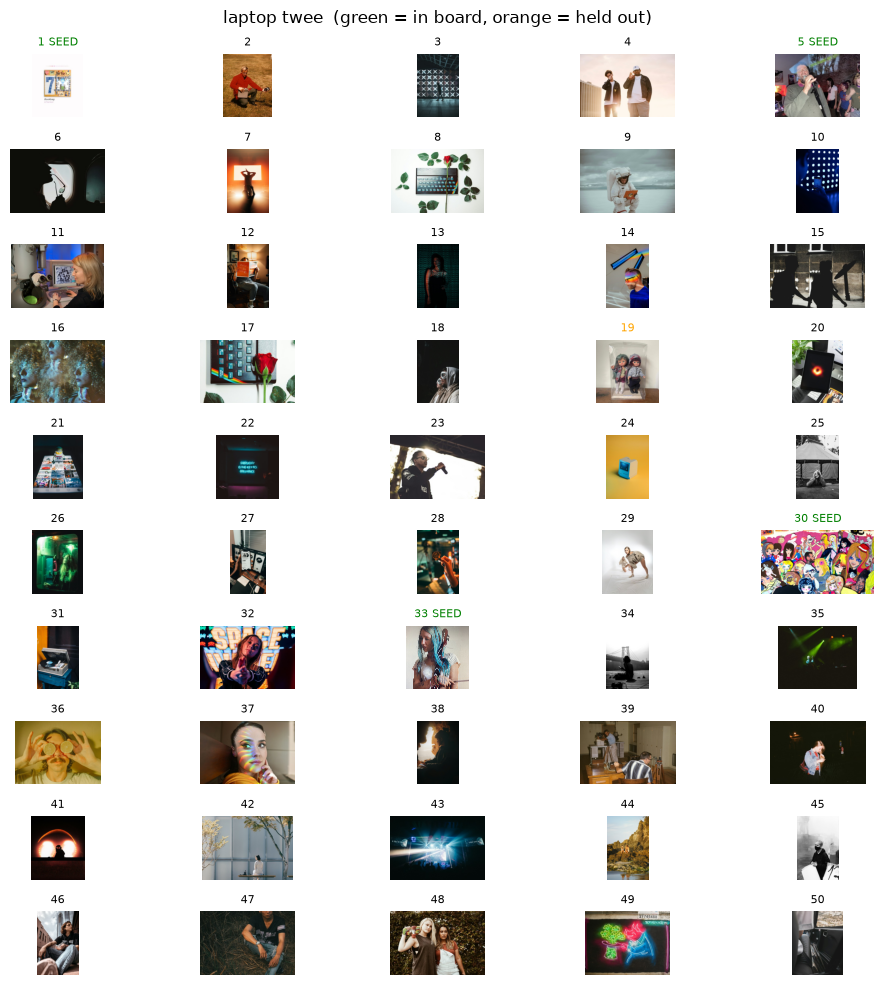

Batches: 100%|██████████| 1/1 [00:00<00:00, 77.48it/s]


       collection_title  relevance
20687               Car   0.993307
43375               car   0.993307
46598               car   0.993307
74904               Car   0.993307
119638              Car   0.993307
2 seed images


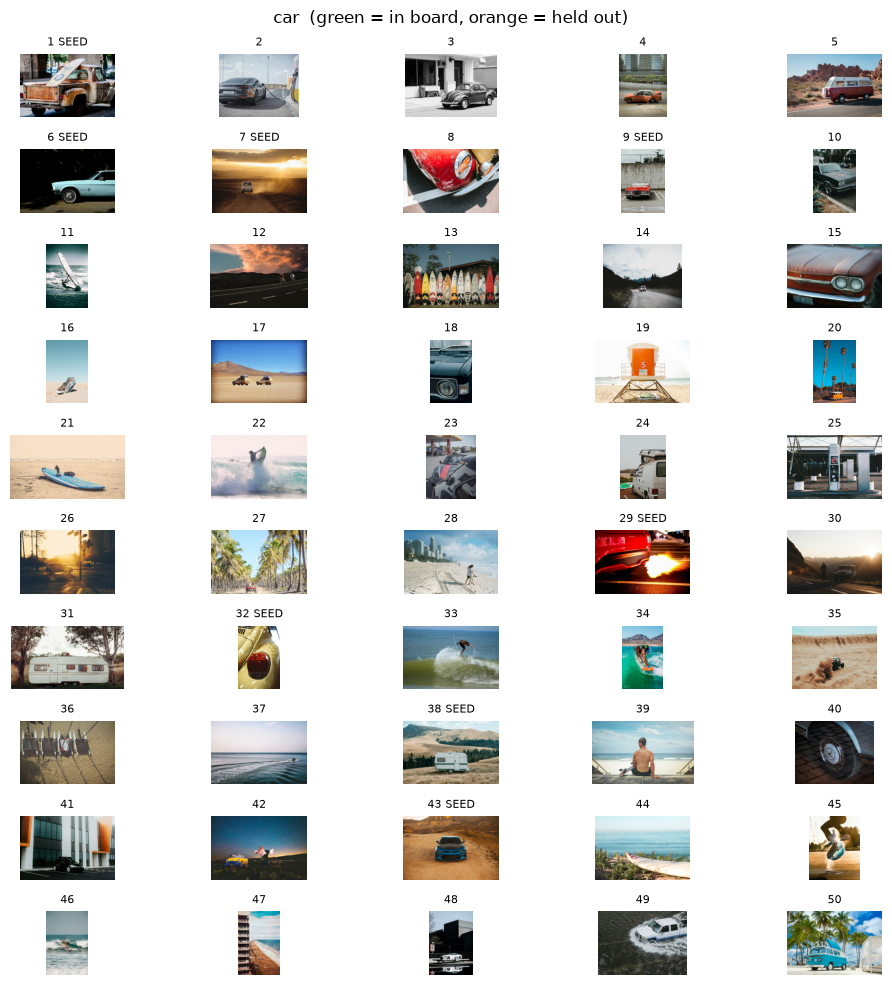

In [67]:
import matplotlib.pyplot as plt

for query in ["laptop twee", "car"]:
    res = search(query)
    fig, axes = plt.subplots(10, 5, figsize=(10, 10))
    for i, ax in enumerate(axes.flat):
        row = res.iloc[i]
        ax.imshow(Image.open(row["image_path"]))
        ax.axis("off")
        ax.set_title(f"{i + 1}{' SEED' if row['seed'] > 0.1 else ''}", fontsize=8,
                     color="orange" if row["photo_id"] in heldout_ids
                     else "green" if row["photo_id"] in inboard_ids else "black")
    fig.suptitle(f"{query}  (green = in board, orange = held out)")
    plt.tight_layout()
    plt.show()

In [68]:
def heldout_ranks(results):
    # results is already sorted best-first; drop in-board images so they don't count
    candidates = results[~results["photo_id"].isin(inboard_ids)].reset_index(drop=True)
    return sorted((candidates.index[candidates["photo_id"].isin(heldout_ids)] + 1).tolist())

heldout_ranks(search("laptop twee"))

Batches: 100%|██████████| 1/1 [00:00<00:00, 55.98it/s]

       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
6 seed images


[17, 69, 367, 1263, 2227]

In [69]:
rows = []
for space_name, space in [("raw siglip", X), ("learned", X_learned)]:
    for seed_cutoff in [0.1, 0.5]:
        for top_matches in [1, 3, 5]:
            for siglip_strength in [0.0, 0.2, 0.5]:
                results = search("laptop twee", seed_cutoff=seed_cutoff, top_matches=top_matches,
                                 visual_space=space, siglip_strength=siglip_strength, verbose=False)
                ranks = heldout_ranks(results)
                rows.append({"space": space_name, "seed_cutoff": seed_cutoff, "top_matches": top_matches,
                             "siglip_strength": siglip_strength, "ranks": ranks,
                             "mean_rank": np.mean(ranks)})

pd.DataFrame(rows).sort_values("mean_rank").head(15)

Batches: 100%|██████████| 1/1 [00:00<00:00, 67.35it/s]


       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
149 seed images


Batches: 100%|██████████| 1/1 [00:00<00:00, 50.36it/s]


       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
149 seed images


Batches: 100%|██████████| 1/1 [00:00<00:00, 83.74it/s]


       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
149 seed images


... (63 outputs left out)

       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
6 seed images


Batches: 100%|██████████| 1/1 [00:00<00:00, 50.68it/s]


       collection_title  relevance
558146      laptop twee   0.993307
4913             Laptop   0.146669
5714             Laptop   0.146669
56098           laptop    0.146669
64313            Laptop   0.146669
6 seed images


,space,seed_cutoff,top_matches,siglip_strength,ranks,mean_rank
31,learned,0.5,3,0.2,"[17, 69, 367, 1263, 2227]",788.6
22,learned,0.1,3,0.2,"[17, 69, 367, 1263, 2227]",788.6
23,learned,0.1,3,0.5,"[19, 55, 558, 1195, 2464]",858.2
32,learned,0.5,3,0.5,"[19, 55, 558, 1195, 2464]",858.2
34,learned,0.5,5,0.2,"[4, 130, 343, 1154, 2737]",873.6
25,learned,0.1,5,0.2,"[4, 130, 343, 1154, 2737]",873.6
26,learned,0.1,5,0.5,"[30, 33, 535, 1119, 2959]",935.2
35,learned,0.5,5,0.5,"[30, 33, 535, 1119, 2959]",935.2
19,learned,0.1,1,0.2,"[134, 205, 631, 1542, 2194]",941.2
28,learned,0.5,1,0.2,"[134, 205, 631, 1542, 2194]",941.2


In [71]:
twee_indices = torch.tensor([photo_to_idx[p] for p in all_ids], device=device)

def twee_closeness(space):
    twee = space[twee_indices]
    within = (twee @ twee.T)[~torch.eye(len(twee), dtype=torch.bool, device=device)]   # twee vs twee
    random_idx = torch.randint(len(space), (2000,), device=device)
    random_pairs = (space[random_idx[:1000]] * space[random_idx[1000:]]).sum(1)       # random vs random
    # how many standard deviations above a random pair the average twee pair is
    return ((within.mean() - random_pairs.mean()) / random_pairs.std()).item()

print("raw siglip:", round(twee_closeness(X), 2))
print("learned:   ", round(twee_closeness(X_learned), 2))

raw siglip: -1.81
learned:    2.1


In [72]:
twee = X_learned[twee_indices]
pair_similarity = twee @ twee.T
pair_similarity.fill_diagonal_(float("nan"))
avg_to_others = torch.nanmean(pair_similarity, dim=1).cpu().numpy()

pd.DataFrame({"photo_id": all_ids, "avg_similarity_to_other_twee": avg_to_others,
              "held_out": [p in heldout_ids for p in all_ids]}).sort_values("avg_similarity_to_other_twee")

,photo_id,avg_similarity_to_other_twee,held_out
5,laptop_twee_5,0.755404,True
4,laptop_twee_4,0.799430,False
2,laptop_twee_2,0.802280,False
9,laptop_twee_9,0.802789,True
7,laptop_twee_7,0.805279,True
1,laptop_twee_1,0.818062,False
8,laptop_twee_8,0.827691,True
3,laptop_twee_3,0.832193,False
6,laptop_twee_6,0.849262,True
0,laptop_twee_0,0.859763,False
